In [1]:
import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


##### Penjelasan :
##### Pada tahap awal ini, sistem memanggil paket pengolah data tabular untuk membuka dan membaca berkas data pelanggan pusat perbelanjaan yang tersimpan dalam format berkas teks terpisah tanda koma, kemudian langsung menampilkan lima baris data teratas ke layar sebagai langkah verifikasi awal bahwa seluruh struktur data telah terbaca dengan baik ke dalam memori komputer. Melalui proses ini, pengguna dapat langsung memeriksa susunan informasi awal dari tabel tersebut, di mana hasil luarannya berupa tampilan sampel data yang memperlihatkan lima baris pelanggan pertama lengkap dengan lima atribut utama, yaitu nomor identitas unik pelanggan, jenis kelamin, usia dalam satuan tahun, estimasi pendapatan tahunan dalam satuan ribuan dolar, serta skor pengeluaran belanja pelanggan dengan rentang skala ukur satu sampai seratus.

In [2]:
# cek missing values
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

##### Penjelasan :
##### Langkah kedua ini difokuskan untuk melakukan pemeriksaan kualitas dan kelengkapan data dengan cara mendeteksi apakah terdapat sel data yang kosong, tidak terisi, atau hilang pada setiap kolom di dalam kumpulan data pelanggan tersebut. Hasil yang ditampilkan dari eksekusi ini adalah daftar rekapitulasi numerik yang menunjukkan angka nol untuk seluruh kolom yang ada, mulai dari identitas, jenis kelamin, umur, pendapatan tahunan, hingga skor pengeluaran belanja, yang menandakan bahwa dataset berada dalam kondisi yang sangat bersih, lengkap seutuhnya tanpa ada satu pun nilai yang bolong, sehingga proses analisis data mining dapat langsung dilanjutkan tanpa memerlukan tindakan pembersihan tambahan seperti pengisian nilai pengganti maupun penghapusan baris data.

In [3]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


##### Penjelasan :
##### Pada sel ini, program menghitung ringkasan parameter statistik deskriptif secara menyeluruh untuk seluruh atribut bertipe numerik di dalam data guna memahami sebaran nilai, variasi, serta kecenderungan pemusatan data pelanggan secara cepat dan akurat. Hasil keluarannya berupa tabel ringkasan matematis yang memuat jumlah total sampel sebanyak dua ratus pelanggan, nilai rata-rata, simpangan baku yang mengukur lebar sebaran data, nilai batas terendah, nilai batas kuartil bawah dua puluh lima persen, nilai titik tengah median lima puluh persen, nilai kuartil atas tujuh puluh lima persen, hingga nilai batas tertinggi, di mana terlihat bahwa rentang usia pelanggan berkisar antara delapan belas hingga tujuh puluh tahun dengan rata-rata tiga puluh delapan tahun, pendapatan tahunan berkisar antara lima belas ribu hingga seratus tiga puluh tujuh ribu dolar, serta skor pengeluaran belanja berkisar dari angka satu hingga sembilan puluh sembilan dengan rata-rata di angka lima puluh.

In [4]:
dataset = df.iloc[:,3:]
dataset.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


##### Penjelasan :
##### Langkah ini bertujuan untuk memotong dan mengisolasi kolom-kolom yang relevan bagi segmentasi dua dimensi, yaitu hanya menyaring kolom indeks ketiga dan keempat yang memuat data pendapatan tahunan serta skor pengeluaran pelanggan, kemudian menampilkan lima baris pertamanya ke layar. Hasil yang diperoleh adalah tampilan tabel baru yang lebih ramping dan terfokus murni pada variabel perilaku keuangan tanpa menyertakan nomor identitas, jenis kelamin, maupun umur pelanggan, sehingga data siap dijadikan masukan utama dalam pemodelan segmentasi pelanggan tahap awal berdasarkan kapasitas pemasukan uang dan intensitas pengeluaran belanja mereka.

In [5]:
x = df.iloc[:, 3]
y = df.iloc[:, 4]

##### Penjelasan :
##### Pada tahap ini, sistem mengekstrak nilai-nilai pendapatan tahunan ke dalam satu variabel penampung sebagai sumbu horizontal dan nilai skor pengeluaran belanja ke dalam variabel penampung lainnya sebagai sumbu vertikal. Proses ini tidak menghasilkan tampilan grafis atau teks cetak apa pun di layar, melainkan menyimpan susunan angka-angka koordinat tersebut ke dalam memori kerja komputer agar dapat langsung digunakan sebagai parameter dalam pembuatan grafik pencar serta perhitungan jarak pada algoritma pengelompokan di tahap-tahap berikutnya.

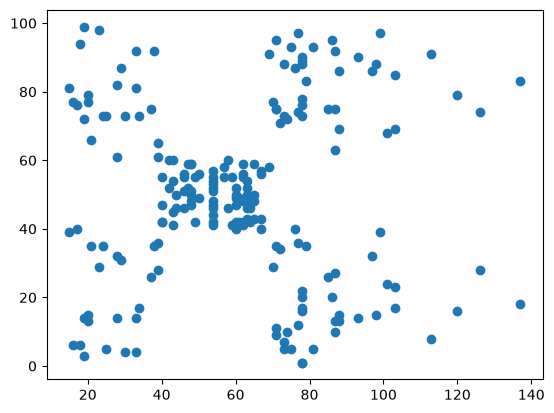

In [6]:
import matplotlib.pyplot as plt
plt.scatter(x, y)
plt.show()

##### Penjelasan :
##### Code ini memanggil modul pembuat visualisasi grafik untuk menggambar diagram pencar dua dimensi yang memetakan hubungan antara tingkat pendapatan tahunan pelanggan pada sumbu mendatar dengan skor pengeluaran belanja pada sumbu tegak. Hasil visual yang ditampilkan adalah hamparan titik-titik data pelanggan yang mulai memperlihatkan formasi pola alami, di mana tampak dengan jelas kecenderungan pemisahan menjadi lima kelompok alami tanpa warna, seperti kelompok berpendapatan rendah belanja rendah, kelompok berpendapatan rendah belanja tinggi, kelompok berpendapatan tinggi belanja rendah, kelompok berpendapatan tinggi belanja tinggi, serta kelompok padat berpenghasilan dan belanja sedang di bagian tengah grafik.

c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

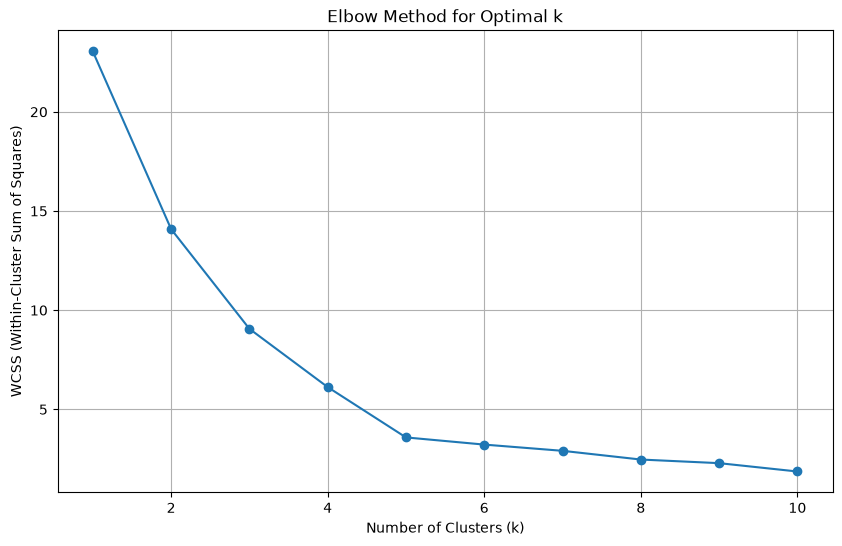

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# Scaling data dengan MinMaxScaler
scaler = MinMaxScaler()

# Mengambil kolom X (index 3) dan Y (index 4) dari DataFrame
X  = pd.DataFrame ({'Anual Income (k$)': x, 'Spending Score (1-100)': y})

X_scaled = scaler.fit_transform(X)

# Menentukan jumlah kluster yang optimal menggunakan Elbow Method
wcss = [] 
for i in range(1, 11): # Coba k dari 1 sampai 10
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)    

# Membuat plot Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

##### Penjelasan :
##### Pada sel ini, data pendapatan dan skor pengeluaran terlebih dahulu diseragamkan rentang nilainya ke dalam skala nol hingga satu menggunakan teknik penskalaan nilai batas agar tidak ada atribut yang mendominasi perhitungan jarak, kemudian dijalankan algoritma pengelompokan secara berulang untuk mencoba variasi jumlah kelompok dari satu hingga sepuluh kelompok sembari menghitung total jumlah kuadrat jarak kesalahan dalam setiap kelompok untuk diplot ke dalam grafik penentuan jumlah kelompok terbaik. Hasil visual yang ditampilkan adalah grafik garis kurva metode siku-siku dengan pola penurunan yang sangat curam pada kelompok satu hingga empat lalu mengalami tekukan atau patahan sudut yang mulai melandai secara nyata tepat di titik angka lima kelompok, yang secara matematis membuktikan bahwa lima kelompok merupakan jumlah pengelompokan yang paling optimal, seimbang, dan efisien untuk data dua dimensi tersebut.

c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


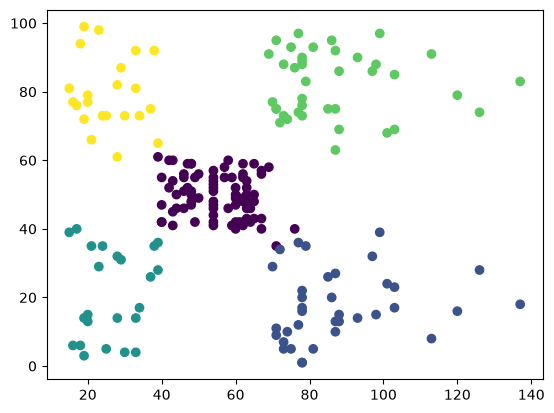

In [9]:
# dari elbow method, nilai k optimal untuk data ini adlaah 5
kmeans = KMeans(n_clusters=5)
kmeans.fit(X)

# plot hasil klaster
plt.scatter(x, y, c=kmeans.labels_)
plt.show()

##### Penjelasan :
##### Berdasarkan kepastian hasil metode siku-siku sebelumnya, sel ini mengonfigurasi algoritma pengelompokan untuk membagi seluruh data pelanggan ke dalam lima kelompok yang pasti, melakukan proses pelatihan model secara langsung pada data, lalu menampilkan kembali diagram pencar dengan memberikan warna yang berbeda untuk masing-masing kelompok pelanggan yang terbentuk. Hasil visual yang ditampilkan adalah diagram pencar dua dimensi dengan pemisahan warna yang sangat rapi dan tegas menjadi lima segmen pelanggan, yaitu segmen berpendapatan tinggi dengan pengeluaran tinggi, segmen berpendapatan tinggi dengan pengeluaran rendah, segmen berpendapatan menengah dengan pengeluaran sedang, segmen berpendapatan rendah dengan pengeluaran rendah, serta segmen berpendapatan rendah namun memiliki tingkat pengeluaran belanja yang tinggi.

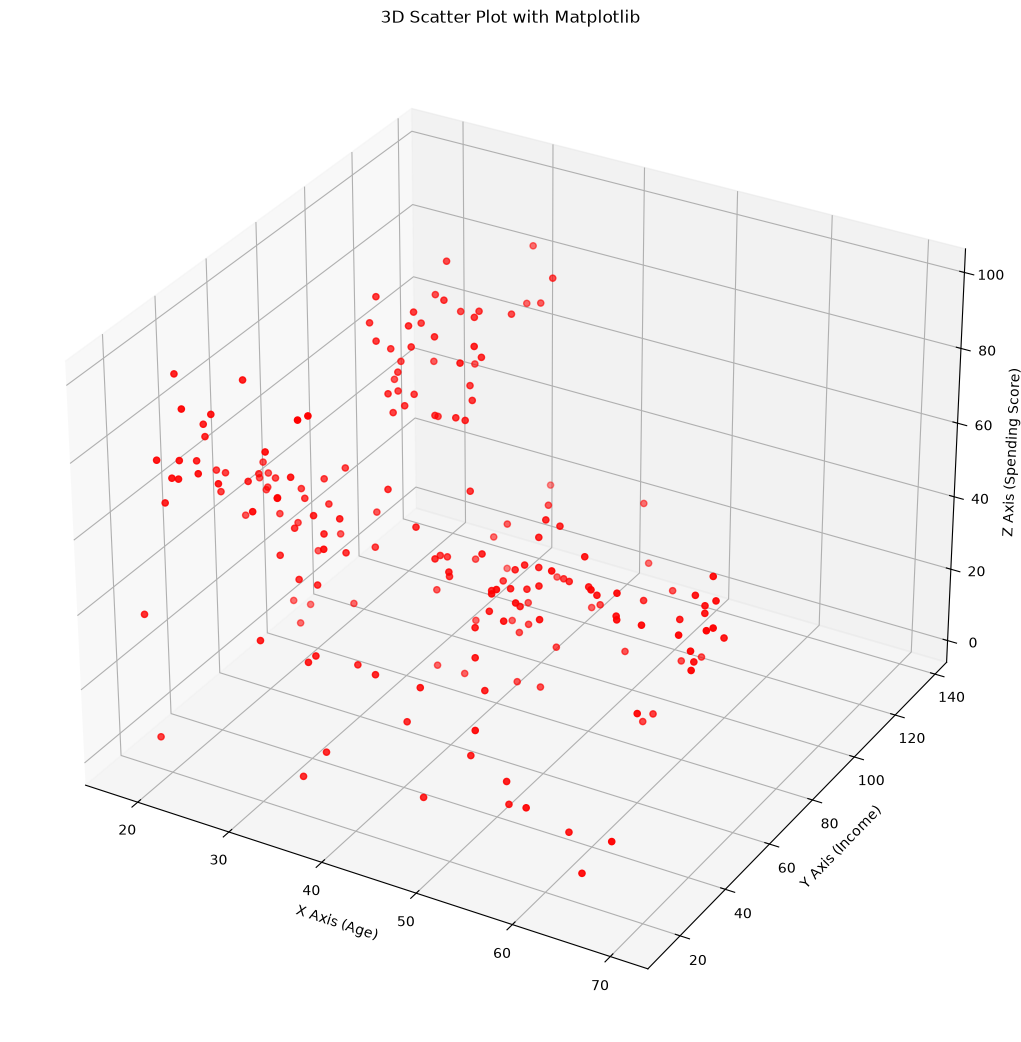

In [10]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Data Age, Annual Incomne, dan Spending Score
x = df.iloc[:, 2]
y = df.iloc[:, 3]
z = df.iloc[:, 4]

# Membuat plot 3D
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(111, projection='3d')

# Plot data
ax.scatter(x, y, z, c='red', marker='o')

# Label sumbu
ax.set_xlabel('X Axis (Age)')
ax.set_ylabel('Y Axis (Income)')
ax.set_zlabel('Z Axis (Spending Score)')

plt.title('3D Scatter Plot with Matplotlib')
plt.show()

##### Penjelasan :
##### Pada tahap ini, analisis ditingkatkan ke tingkat multidimensi dengan memasukkan faktor usia pelanggan ke samping pendapatan tahunan dan skor pengeluaran belanja, lalu memproyeksikan ketiga variabel tersebut ke dalam ruang visualisasi tiga dimensi menggunakan modul grafik spasial. Hasil keluarannya adalah grafik sebar tiga dimensi berukuran besar dengan titik-titik data berwarna merah pada bidang sumbu ruang usia, pendapatan, dan pengeluaran, yang memungkinkan pengamat melihat pola sebaran pelanggan secara lebih utuh dan mendalam dari tiga arah pandang sekaligus guna mengetahui bagaimana faktor usia turut memengaruhi daya beli serta gaya belanja para pelanggan di pusat perbelanjaan.

c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

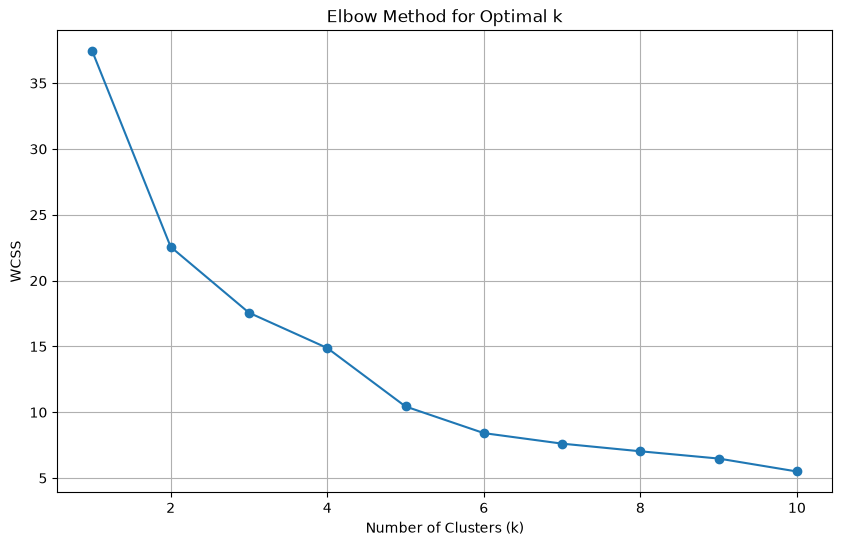

In [11]:
# Menggabungkan data X, Y Z menjadi array untuk clustering
X = np.array(list(zip(x, y, z)))

# Scalling data dengann MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Menentukan jumlah klaster optimal dengan Elbow Method
wcss = []
for i in range(1, 11): 
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

##### Penjelasan :
##### Sel ini bertugas merangkai ketiga variabel usia, pendapatan, dan skor pengeluaran menjadi satu kesatuan susunan matriks data terpadu, menyamakan rentang nilainya menggunakan penskalaan nilai batas antara nol hingga satu, kemudian menguji kembali total jumlah kuadrat jarak kesalahan untuk variasi satu sampai sepuluh kelompok pada ruang tiga dimensi tersebut. Hasil yang ditampilkan adalah grafik garis metode siku-siku tiga dimensi yang memperlihatkan bahwa dengan penambahan dimensi usia, kelokan atau titik patahan kurva yang paling stabil dan melandai terjadi pada angka enam kelompok, yang membuktikan bahwa pada ruang data tiga dimensi pengelompokan pelanggan menjadi enam segmen adalah pilihan yang paling optimal dan seimbang.

c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


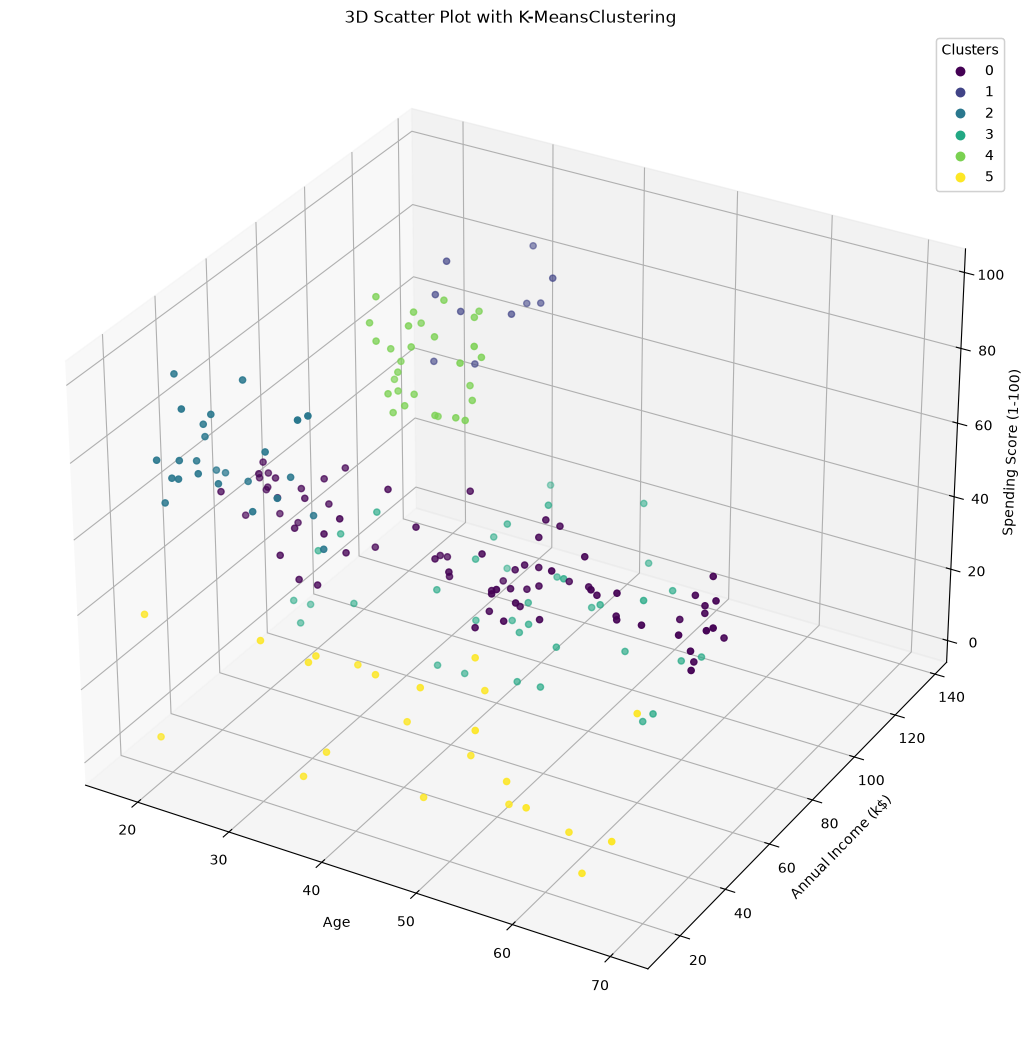

In [15]:
# Pilih k optimal setelah melihat Elbow
kmeans = KMeans(n_clusters=6, random_state=42)
clusters = kmeans.fit_predict(X)

# Menambahkan hasil kalster ke DataFrame
df['Cluster'] = clusters

# Visualisasi hasil klaster dalam 3D

# Plot data dengan warna berdasarkan kalster
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(111, projection='3d')

# Plot setaip titik dengan warna sesuai kalster
scatter = ax.scatter(x, y, z, c=clusters, cmap='viridis', marker='o')

# Label sumbu
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')

# Menampilkan legenda kalster 
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)

plt.title('3D Scatter Plot with K-MeansClustering')
plt.show()

##### Penjelasan :
##### Pada sel penutup ini, model algoritma pengelompokan dijalankan dengan menetapkan enam kelompok optimal pada gabungan data tiga dimensi, hasilnya disimpan langsung sebagai label kelompok baru di dalam tabel data utama, lalu divisualisasikan ke dalam diagram pencar tiga dimensi dengan gradasi warna warni yang dilengkapi kotak keterangan kelompok untuk memudahkan pembacaan segmen. Hasil akhirnya adalah tampilan grafik tiga dimensi yang memperlihatkan partisi enam kelompok pelanggan dengan warna berbeda yang mencerminkan profil demografis belanja yang mendalam, seperti kelompok pelanggan muda berpendapatan tinggi yang gemar berbelanja, kelompok lansia berpendapatan stabil dengan belanja terencana, hingga kelompok berpenghasilan rendah dengan pola konsumsi yang bervariasi sesuai kelompok usianya, yang memberikan wawasan strategis bagi pihak manajemen pusat perbelanjaan dalam menyusun program pemasaran yang tepat sasaran.